# Lab 02 - Hồi quy logistic

- Code thực hành và bài tập dựa trên PDF giảng viên
- Dữ liệu cần đặt trong thư mục `data/`: `sinh_vien.csv`
- Tài liệu PDF không kèm CSV gốc nên chưa có output đầy đủ
- Chạy từng cell từ trên xuống sau khi thêm đủ dữ liệu

## 1 - Đọc dữ liệu sinh viên

In [1]:
# -*- coding: utf-8 -*-

import pandas as pd

df = pd.read_csv("data/sinh_vien.csv")

print("Kich thuoc bang (so dong, so cot):", df.shape)
print()

print("Nam dong dau tien:")
print(df.head())
print()

# Cột qua_mon chỉcó hai giá trị, đếm sốlần xuất hiện từng giá trị
print("So sinh vien theo ket qua:")
print(df["qua_mon"].value_counts())
print()

print("Ty le qua mon:", round(df["qua_mon"].mean(), 4))
print()

# So sánh số giờ ôn trung bình của hai nhóm
print("So gio on trung binh theo nhom:")
print(df.groupby("qua_mon")["gio_on"].mean().round(2))


Kich thuoc bang (so dong, so cot): (120, 3)

Nam dong dau tien:
   gio_on  diem_giua_ky  qua_mon
0     5.5           3.0        0
1    19.0           6.0        1
2    14.0           7.7        0
3    11.0           3.1        0
4    10.5           5.8        1

So sinh vien theo ket qua:
qua_mon
1    71
0    49
Name: count, dtype: int64

Ty le qua mon: 0.5917

So gio on trung binh theo nhom:
qua_mon
0     8.29
1    19.89
Name: gio_on, dtype: float64


## 2 - Hàm Sigmoid

In [2]:
# -*- coding: utf-8 -*-

import numpy as np


def sigmoid(z):
    """Ep mot so thuc bat ky ve khoang tu 0 toi 1."""
    return 1 / (1 + np.exp(-z))


print("Bang gia tri cua ham sigmoid")
print("  z       sigmoid(z)")
for z in [-6, -4, -2, -1, 0, 1, 2, 4, 6]:
    print(f"{z:3d}       {sigmoid(z):.4f}")
print()

# Hai tính chất cần tự kiểm chứng
print("Kiem tra sigmoid(-z) = 1 - sigmoid(z):")
for z in [1.0, 2.5, 3.7]:
    trai = sigmoid(-z)
    phai = 1 - sigmoid(z)
    print(f"z = {z}: {trai:.6f} va {phai:.6f}")
print()

# Thử với một mô hình giả định w = 0.4 và b = -5
w, b = 0.4, -5.0
print(f"Mo hinh gia dinh: w = {w}, b = {b}")
print(" So gio on    z = w*x + b    Xac suat qua mon")
for gio in [5, 10, 12.5, 15, 20, 25]:
    z = w * gio + b
    print(f"{gio:5.1f}          {z:6.2f}            {sigmoid(z):.4f}")


Bang gia tri cua ham sigmoid
  z       sigmoid(z)
 -6       0.0025
 -4       0.0180
 -2       0.1192
 -1       0.2689
  0       0.5000
  1       0.7311
  2       0.8808
  4       0.9820
  6       0.9975

Kiem tra sigmoid(-z) = 1 - sigmoid(z):
z = 1.0: 0.268941 va 0.268941
z = 2.5: 0.075858 va 0.075858
z = 3.7: 0.024127 va 0.024127

Mo hinh gia dinh: w = 0.4, b = -5.0
 So gio on    z = w*x + b    Xac suat qua mon
  5.0           -3.00            0.0474
 10.0           -1.00            0.2689
 12.5            0.00            0.5000
 15.0            1.00            0.7311
 20.0            3.00            0.9526
 25.0            5.00            0.9933


## 3 - Khớp Logistic Regression bằng Scikit-learn

In [3]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("data/sinh_vien.csv")

# X phải là bảng hai chiều nên viết hai cặp ngoặc vuông.
# y là dãy một chiều nên chỉmột cặp.
X = df[["gio_on"]]
y = df["qua_mon"]

mo_hinh = LogisticRegression()
mo_hinh.fit(X, y)

w = float(mo_hinh.coef_[0][0])
b = float(mo_hinh.intercept_[0])

print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

# Sốgiờ ôn mà mô hình phân vân đúng năm mươi năm mươi
print(f"So gio on ung voi xac suat 0.5: {-b / w:.2f} gio")
print()

can_moi = pd.DataFrame({"gio_on": [5.0, 10.0, 13.0, 20.0, 28.0]})
xac_suat = mo_hinh.predict_proba(can_moi)[:, 1]
nhan = mo_hinh.predict(can_moi)

print("Du doan cho nam ban moi:")
print(" So gio on    Xac suat qua    Nhan mo hinh dua ra")
for gio, p, n in zip(can_moi["gio_on"], xac_suat, nhan):
    print(f"{gio:5.1f}          {p:.4f}           {n}")


He so goc w = 0.392819
He so chan b = -5.064890

So gio on ung voi xac suat 0.5: 12.89 gio

Du doan cho nam ban moi:
 So gio on    Xac suat qua    Nhan mo hinh dua ra
  5.0          0.0431           0
 10.0          0.2429           0
 13.0          0.5104           1
 20.0          0.9422           1
 28.0          0.9974           1


## 4 - Đánh giá mô hình

In [4]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

# stratify=y giữđúng tỷ lệqua và rớt ở cảhai phần sau khi chia
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("So sinh vien de hoc:", len(X_train))
print("So sinh vien de kiem tra:", len(X_test))
print()

mo_hinh = LogisticRegression()
mo_hinh.fit(X_train, y_train)

y_pred = mo_hinh.predict(X_test)

# Thứ tựbốn ô do scikit-learn quy định là TN, FP, FN, TP
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f"TN = {tn:2d}  doan rot, that su rot")
print(f"FP = {fp:2d}  doan qua, that ra rot")
print(f"FN = {fn:2d}  doan rot, that ra qua")
print(f"TP = {tp:2d}  doan qua, that su qua")
print()

print(f"Accuracy = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall = {recall_score(y_test, y_pred):.4f}")
print(f"F1 = {f1_score(y_test, y_pred):.4f}")
print()

# Tựtính lại bằng tay đểđối chiếu với thư viện
print("Tu tinh lai bang cong thuc:")
n = len(y_test)
print(f"Accuracy = ({tp} + {tn}) / {n} = {(tp + tn) / n:.4f}")
print(f"Precision = {tp} / ({tp} + {fp}) = {tp / (tp + fp):.4f}")
print(f"Recall = {tp} / ({tp} + {fn}) = {tp / (tp + fn):.4f}")


So sinh vien de hoc: 90
So sinh vien de kiem tra: 30

Ma tran nham lan
TN =  9  doan rot, that su rot
FP =  3  doan qua, that ra rot
FN =  1  doan rot, that ra qua
TP = 17  doan qua, that su qua

Accuracy = 0.8667
Precision = 0.8500
Recall = 0.9444
F1 = 0.8947

Tu tinh lai bang cong thuc:
Accuracy = (17 + 9) / 30 = 0.8667
Precision = 17 / (17 + 3) = 0.8500
Recall = 17 / (17 + 1) = 0.9444


## 5 - Thay đổi ngưỡng quyết định

In [5]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = LogisticRegression().fit(X_train, y_train)

# predict_proba trả vềhai cột, cột 0 cho lớp 0 và cột 1 cho lớp 1
p = mo_hinh.predict_proba(X_test)[:, 1]

print("Nguong  So ban bi doan la qua  Precision  Recall")
for nguong in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    y_pred = (p >= nguong).astype(int)
    pre = precision_score(y_test, y_pred, zero_division=1)
    rec = recall_score(y_test, y_pred, zero_division=0)
    print(f" {nguong:.1f}              {y_pred.sum():3d}             "
          f"{pre:.4f}      {rec:.4f}")
print()

print("Doc bang tren tu duoi len:")
print("Nguong cang cao thi mo hinh cang kho tinh,")
print("precision tang nhung recall giam. Nguong thap thi nguoc lai.")


Nguong  So ban bi doan la qua  Precision  Recall
 0.2               24             0.7500      1.0000
 0.3               20             0.8500      0.9444
 0.4               20             0.8500      0.9444
 0.5               20             0.8500      0.9444
 0.6               16             1.0000      0.8889
 0.7               15             1.0000      0.8333
 0.8               13             1.0000      0.7222

Doc bang tren tu duoi len:
Nguong cang cao thi mo hinh cang kho tinh,
precision tang nhung recall giam. Nguong thap thi nguoc lai.


## 6 - Hồi quy Logistic với hai biến

In [6]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/sinh_vien.csv")
y = df["qua_mon"]

# Chỉ đổi đúng một chỗ: danh sách cột đưa vào X
for ten, cot in [("Mot bien", ["gio_on"]),
                 ("Hai bien", ["gio_on", "diem_giua_ky"])]:
    X = df[cot]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=17, stratify=y
    )
    mo_hinh = LogisticRegression().fit(X_train, y_train)
    do_chinh_xac = accuracy_score(y_test, mo_hinh.predict(X_test))
    print(f"{ten}: accuracy tren tap kiem tra = {do_chinh_xac:.4f}")
print()

# Xem kỹhệ sốcủa mô hình hai biến
X = df[["gio_on", "diem_giua_ky"]]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = LogisticRegression().fit(X_train, y_train)

print("He so cua tung bien:")
for ten_cot, he_so in zip(X.columns, mo_hinh.coef_[0]):
    print(f"{ten_cot:14s} {he_so:+.4f}")
print(f"{'he so chan':14s} {mo_hinh.intercept_[0]:+.4f}")
print()
print("Ca hai he so deu duong, nghia la on nhieu hon va")
print("diem giua ky cao hon deu lam tang xac suat qua mon.")


Mot bien: accuracy tren tap kiem tra = 0.8667
Hai bien: accuracy tren tap kiem tra = 0.9000

He so cua tung bien:
gio_on         +0.3035
diem_giua_ky   +0.5885
he so chan     -6.9811

Ca hai he so deu duong, nghia la on nhieu hon va
diem giua ky cao hon deu lam tang xac suat qua mon.


# Bài tập

## Bài tập 1 - Thống kê theo nhóm

In [7]:
import pandas as pd

df = pd.read_csv('data/sinh_vien.csv')
nhom_cao = df[df['diem_giua_ky'] >= 7]
nhom_thap = df[df['diem_giua_ky'] < 7]

print('So ban diem giua ky tu 7 tro len:', len(nhom_cao))
print(f'Ty le qua mon nhom diem >= 7: {nhom_cao["qua_mon"].mean():.4f}')
print(f'Ty le qua mon nhom diem < 7 : {nhom_thap["qua_mon"].mean():.4f}')

chenh_lech = nhom_cao['qua_mon'].mean() - nhom_thap['qua_mon'].mean()
print(f'Chenh lech ty le qua mon: {chenh_lech:+.4f}')
if chenh_lech > 0:
    print('Nhan xet: nhom diem cao co ty le qua mon cao hon.')
elif chenh_lech < 0:
    print('Nhan xet: nhom diem cao co ty le qua mon thap hon.')
else:
    print('Nhan xet: hai nhom co ty le qua mon bang nhau.')


So ban diem giua ky tu 7 tro len: 31
Ty le qua mon nhom diem >= 7: 0.9032
Ty le qua mon nhom diem < 7 : 0.4831
Chenh lech ty le qua mon: +0.4201
Nhan xet: nhom diem cao co ty le qua mon cao hon.


- Chia sinh viên thành hai nhóm theo điểm giữa kỳ rồi dùng `mean()` để tính tỷ lệ qua môn
- Chênh lệch giữa hai tỷ lệ giúp thấy điểm giữa kỳ có liên quan đến kết quả qua môn hay không

## Bài tập 2 - Vẽ hàm sigmoid

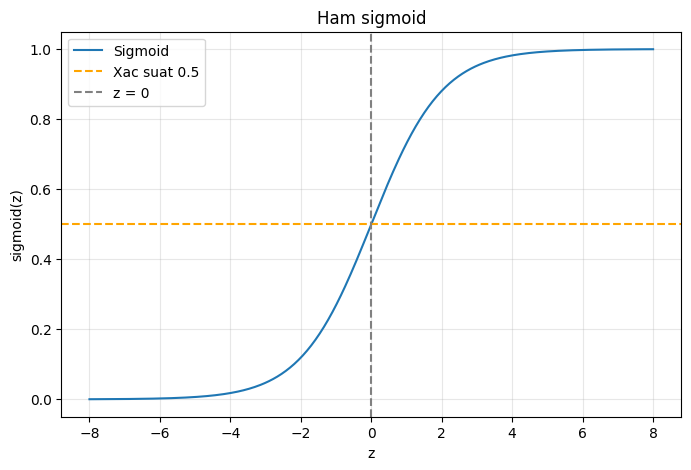

Da luu bieu do: sigmoid.png


In [8]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-8, 8, 400)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, label='Sigmoid')
plt.axhline(y=0.5, color='orange', linestyle='--', label='Xac suat 0.5')
plt.axvline(x=0, color='gray', linestyle='--', label='z = 0')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.title('Ham sigmoid')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('sigmoid.png', dpi=150, bbox_inches='tight')
plt.show()
print('Da luu bieu do: sigmoid.png')


- Khi `z = 0`, sigmoid bằng `0.5`
- Hàm sigmoid đưa các giá trị về khoảng 0 đến 1 nên phù hợp để biểu diễn xác suất

## Bài tập 3 - Dự đoán cho một bạn cụ thể

In [9]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('data/sinh_vien.csv')
mo_hinh = LogisticRegression().fit(df[['gio_on']], df['qua_mon'])
w = mo_hinh.coef_[0, 0]
b = mo_hinh.intercept_[0]

def du_doan(gio):
    z = w * gio + b
    p = 1 / (1 + np.exp(-z))
    nhan = 1 if p >= 0.5 else 0
    print(f'{gio:5.2f} gio | z = {z:8.4f} | p(qua) = {p:.4f} | nhan = {nhan}')

for gio in [3, 8, 12.89, 18, 26]:
    du_doan(gio)

print(f'Ranh gioi xac suat 0.5: {-b / w:.4f} gio')


 3.00 gio | z =  -3.8864 | p(qua) = 0.0201 | nhan = 0
 8.00 gio | z =  -1.9223 | p(qua) = 0.1276 | nhan = 0
12.89 gio | z =  -0.0015 | p(qua) = 0.4996 | nhan = 0
18.00 gio | z =   2.0059 | p(qua) = 0.8814 | nhan = 1
26.00 gio | z =   5.1484 | p(qua) = 0.9942 | nhan = 1
Ranh gioi xac suat 0.5: 12.8937 gio


- Giá trị `z = w * gio + b` gần 0 thì xác suất qua môn gần 0.5
- Mốc 12.89 giờ gần ranh giới quyết định nếu hệ số học được tương ứng với dữ liệu trong PDF

## Bài tập 4 - Tự tính bốn thước đo

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/sinh_vien.csv')
X = df[['gio_on']]
y = df['qua_mon']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = LogisticRegression().fit(X_tr, y_tr)
y_du_doan = mo_hinh.predict(X_te)

tn, fp, fn, tp = confusion_matrix(y_te, y_du_doan, labels=[0, 1]).ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print(f'Accuracy : {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall   : {recall:.4f}')
print(f'F1-score : {f1:.4f}')


TN=9, FP=3, FN=1, TP=17
Accuracy : 0.8667
Precision: 0.8500
Recall   : 0.9444
F1-score : 0.8947


- Accuracy là tỷ lệ dự đoán đúng trên tất cả sinh viên
- Precision cho biết trong số bạn được dự đoán qua môn có bao nhiêu bạn qua thật
- Recall cho biết trong số bạn qua môn thật, mô hình nhận ra bao nhiêu bạn
- F1 kết hợp Precision và Recall để đánh giá cân bằng hơn

## Bài tập 5 - Dò ngưỡng tốt nhất theo F1

In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/sinh_vien.csv')
X_tr, X_te, y_tr, y_te = train_test_split(
    df[['gio_on']], df['qua_mon'], test_size=0.25,
    random_state=17, stratify=df['qua_mon']
)
mo_hinh = LogisticRegression().fit(X_tr, y_tr)
p = mo_hinh.predict_proba(X_te)[:, 1]

bang = []
print('Nguong     F1-score')
for nguong in np.arange(0.05, 1.0, 0.05):
    y_pred = (p >= nguong).astype(int)
    f1 = f1_score(y_te, y_pred, zero_division=0)
    bang.append((float(nguong), float(f1)))
    print(f'{nguong:5.2f}      {f1:.4f}')

nguong_tot, f1_tot = max(bang, key=lambda item: item[1])
print(f'Nguong tot nhat: {nguong_tot:.2f} | F1 = {f1_tot:.4f}')
print('Nguong tot nhat co bang 0.5 khong?', np.isclose(nguong_tot, 0.5))


Nguong     F1-score
 0.05      0.7826
 0.10      0.8182
 0.15      0.8182
 0.20      0.8571
 0.25      0.9000
 0.30      0.8947
 0.35      0.8947
 0.40      0.8947
 0.45      0.8947
 0.50      0.8947
 0.55      0.8889
 0.60      0.9412
 0.65      0.9412
 0.70      0.9091
 0.75      0.8750
 0.80      0.8387
 0.85      0.8000
 0.90      0.5600
 0.95      0.4348
Nguong tot nhat: 0.60 | F1 = 0.9412
Nguong tot nhat co bang 0.5 khong? False


- Ngưỡng cho F1 cao nhất không nhất thiết bằng `0.5`
- Bài này dò trên tập kiểm tra theo đề; khi làm dự án thật nên dò trên tập validation riêng

## Bài tập 6 - Đổi lớp dương rồi chấm lại

In [12]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/sinh_vien.csv')
X_tr, X_te, y_tr, y_te = train_test_split(
    df[['gio_on']], df['qua_mon'], test_size=0.25,
    random_state=17, stratify=df['qua_mon']
)
mo_hinh = LogisticRegression().fit(X_tr, y_tr)
y_pred = mo_hinh.predict(X_te)

for lop, ten in [(1, 'Qua mon'), (0, 'Rot mon')]:
    precision = precision_score(y_te, y_pred, pos_label=lop, zero_division=0)
    recall = recall_score(y_te, y_pred, pos_label=lop, zero_division=0)
    print(f'{ten:10s} | Precision = {precision:.4f} | Recall = {recall:.4f}')


Qua mon    | Precision = 0.8500 | Recall = 0.9444
Rot mon    | Precision = 0.9000 | Recall = 0.7500


- Chọn `pos_label=0` nghĩa là đang xem lớp rớt môn là lớp cần phát hiện
- Hai bộ điểm khác nhau vì TP, FP và FN được tính theo hai lớp khác nhau